# 02. U-Net on CH4Net: paper split and site-disjoint split

U-Net (ResNet-34 encoder, ImageNet weights) trained on the CH4Net release (Vaughan et al. 2024,
HF `av555/ch4net`, CC BY-NC-ND 4.0), option (a): CH4Net's own uint8 arrays. Inputs are the 12 CH4Net
bands plus the decoded MBMP field (13 channels). Augmentation: flips and 90 degree rotations only.

Two evaluations on 2021 images:
- **Paper split**: CH4Net's folders (train 2017 to 2020, test 2021). The same 23 sites are in train and
  test, so this is for reproducing the paper only.
- **Site-disjoint split** (hard rule 3): 23 sites in 17 groups at 2 km; test sites are never trained on.
  Site ids for every CH4Net image come from `plumescout.ch4net_sites` .

**Metric.** The paper's 84% is scene-level recall: a scene is flagged if a connected region of more than
115 px has probability >= 0.25. All tables use that rule. Plume-level counts are in each run's `metrics.json`.

This notebook only reads saved run outputs in `models/` (gitignored); it does not train.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from plumescout.config import resolve_path

MODELS = resolve_path("models")
FIG = resolve_path("figures")
FIG.mkdir(exist_ok=True)


def load(run: str) -> dict:
    return json.loads((MODELS / run / "metrics.json").read_text())

## Paper split vs site-disjoint split (best checkpoint, paper scene rule)

In [2]:
paper = {"model": "Paper (CH4Net, all bands)", "test scenes": 2473, "plume scenes": 275}
paper |= {"sites": 23, "thr": 0.25, "recall": 0.84, "precision": 0.30, "fpr": 0.24}
paper |= {"balanced_acc": 0.76, "CI": "not reported"}
rows = [paper]
for run, label, ci_key in [
    ("paper_allbands_30ep", "Ours, paper split", "ci95_scene_bootstrap"),
    ("site_year_allbands_20ep", "Ours, site-disjoint", "ci95_site_bootstrap"),
]:
    m = load(run)
    t = m["scene_rule"]["test"]["thr_0.25"]
    ci = t.get(ci_key)
    rows.append(
        {
            "model": label,
            "test scenes": t["n_scenes"],
            "plume scenes": t["n_positive_scenes"],
            "sites": len(m["test_sites"]) if m.get("test_sites") else 23,
            "thr": 0.25,
            "recall": round(t["recall"], 3),
            "precision": round(t["precision"], 3),
            "fpr": round(t["fpr"], 3),
            "balanced_acc": round(t["balanced_accuracy"], 3),
            "CI": (
                f"{ci_key.split('_')[1]}-level, bal. acc. [{ci['balanced_accuracy'][0]:.3f}, "
                f"{ci['balanced_accuracy'][1]:.3f}]"
            )
            if ci
            else "project log",
        }
    )
table = pd.DataFrame(rows)
table

,model,test scenes,plume scenes,sites,thr,recall,precision,fpr,balanced_acc,CI
0,"Paper (CH4Net, all bands)",2473,275,23,0.25,0.840,0.300,0.240,0.760,not reported
1,"Ours, paper split",2473,275,23,0.25,0.884,0.214,0.406,0.739,project log
2,"Ours, site-disjoint",583,48,7,0.25,0.521,0.176,0.219,0.651,project log


The paper-split CI is a scene-level bootstrap (optimistic: scenes repeat within sites). The site-disjoint
CI resamples the 7 test sites. The site-disjoint run's `metrics.json` was written before site CIs were
added to `train.py`; its site-level CI comes from `site_bootstrap.json`.

In [3]:
sb = json.loads((MODELS / "site_year_allbands_20ep" / "site_bootstrap.json").read_text())
{k: v for k, v in sb["best"]["thr_0.25"].items()}

{'recall': [0.521, [0.1, 0.795]],
 'precision': [0.176, [0.007, 0.361]],
 'fpr': [0.219, [0.092, 0.403]],
 'balanced_accuracy': [0.651, [0.411, 0.763]]}

## Validation curves: checkpoint choice sets the operating point

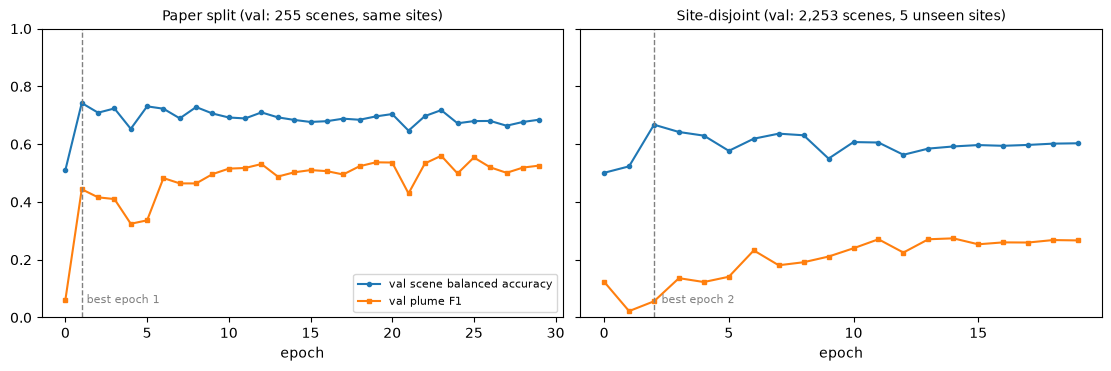

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained", sharey=True)
for ax, run, title in [
    (axes[0], "paper_allbands_30ep", "Paper split (val: 255 scenes, same sites)"),
    (axes[1], "site_year_allbands_20ep", "Site-disjoint (val: 2,253 scenes, 5 unseen sites)"),
]:
    csv = next((MODELS / run / "lightning_logs").glob("*/metrics.csv"))
    d = pd.read_csv(csv).dropna(subset=["val_scene_bacc"])
    ax.plot(d.epoch, d.val_scene_bacc, marker="o", ms=3, label="val scene balanced accuracy")
    ax.plot(d.epoch, d.val_plume_f1, marker="s", ms=3, label="val plume F1")
    best = load(run)["best_epoch"]
    ax.axvline(best, color="grey", ls="--", lw=1)
    ax.text(best + 0.3, 0.05, f"best epoch {best}", color="grey", fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("epoch")
    ax.xaxis.get_major_locator().set_params(integer=True)
    ax.set_ylim(0, 1)
axes[0].legend(loc="lower right", fontsize=8)
fig.savefig(FIG / "02_val_curves.png", dpi=150)

## Site-disjoint test: results by site (best checkpoint, threshold 0.10 chosen on val)

In [5]:
per = pd.DataFrame(sb["best"]["per_site_thr_0.1"])
per["missed"] = per.n_pos - per.detected
per["plume_free"] = per.n - per.n_pos
per

,site,n,n_pos,detected,false_flags,fpr,missed,plume_free
0,T10,146.0,2.0,0.0,20.0,0.139,2.0,144.0
1,T14,73.0,27.0,27.0,28.0,0.609,0.0,46.0
2,T15,73.0,0.0,0.0,16.0,0.219,0.0,73.0
3,T16,73.0,0.0,0.0,32.0,0.438,0.0,73.0
4,T17,73.0,7.0,1.0,4.0,0.061,6.0,66.0
5,T18,72.0,12.0,6.0,16.0,0.267,6.0,60.0
6,T23,73.0,0.0,0.0,50.0,0.685,0.0,73.0


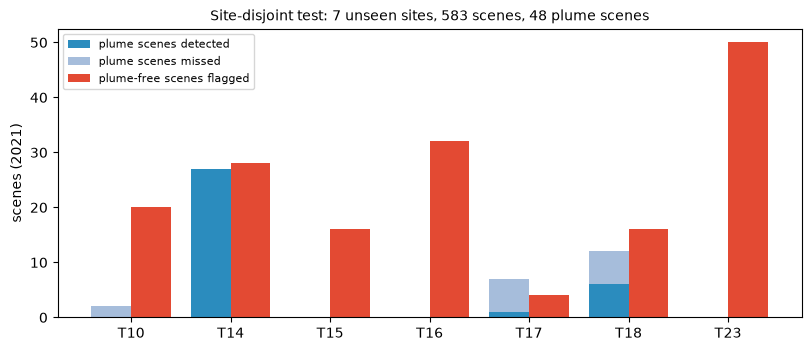

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
x = range(len(per))
ax.bar(x, per.detected, width=0.4, label="plume scenes detected", color="#2b8cbe")
ax.bar(x, per.missed, width=0.4, bottom=per.detected, label="plume scenes missed", color="#a6bddb")
xs = [i + 0.4 for i in x]
ax.bar(xs, per.false_flags, width=0.4, label="plume-free scenes flagged", color="#e34a33")
ax.set_xticks([i + 0.2 for i in x], per.site)
ax.set_ylabel("scenes (2021)")
ax.set_title("Site-disjoint test: 7 unseen sites, 583 scenes, 48 plume scenes", fontsize=10)
ax.legend(fontsize=8)
fig.savefig(FIG / "02_site_disjoint_by_site.png", dpi=150)

## Reading

- On the paper split the model reaches the paper's scene recall (0.884 vs 0.84) at a more liberal
  operating point (FPR 0.406 vs 0.24); balanced accuracy 0.739 vs 0.76.
- On unseen sites balanced accuracy drops to 0.651 at threshold 0.25, with a site-level CI of roughly
  0.41 to 0.76. Recall is carried by T14 (27 of 48 plume scenes), where the model flags most days.
  Without T14, 7 of 21 plume scenes are detected.
- False flags vary strongly by site (T23: 50 of 73 plume-free scenes flagged; T17: 4 of 66).
- Gulf sites are unseen by design, so the site-disjoint numbers are the relevant expectation for Phase 4.
- Caveats: one split, one seed; CH4Net inputs are uint8 display values rather than reflectance.